# 1. The question, and what we can actually measure

**Series:** 1 question & data · 2 pixels & indices · 3 labels · 4 baselines & splits ·
5 the model · 6 evaluation & uncertainty · 7 area, level & radar · 8 transfer to small reservoirs

This project asks whether a deep-learning model, pretrained on satellite imagery with
[TorchGeo](https://torchgeo.readthedocs.io), maps the surface of Texas reservoirs better than
a classic one-line water index. It also asks whether radar can do the job when clouds block
the optical satellites.

Before touching a model it is worth slowing down on two things that decide what *any*
answer can mean:

1. **What is the ground truth, and how was it made?** Here the "official" lake area comes from
   the Texas Water Development Board (TWDB). We will see that it isn't a measurement of area at
   all.
2. **What data will we actually get?** Optical satellites can't see through cloud. How often
   does that happen over these lakes, and in which months?

> Running these notebooks: they read files written by the pipeline (`make all`). The executed
> copies in this folder already contain all outputs, so you can just read them on GitHub.

In [1]:
from hlw.nb import BLUE, GREEN, GREY, ORANGE, setup

setup()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hlw import config as C
from hlw import levels, scenes

LAKES = C.lakes()
pd.DataFrame([{"key": k, "name": v.name, "TWDB slug": v.twdb,
               "level swings a lot?": v.dynamic} for k, v in LAKES.items()])

,key,name,TWDB slug,level swings a lot?
0,buchanan,Lake Buchanan,buchanan,True
1,inks,Inks Lake,inks,False
2,lbj,Lake LBJ,lyndon-b-johnson,False
3,marble_falls,Lake Marble Falls,marble-falls,False
4,travis,Lake Travis,travis,True


## The five Highland Lakes

The Highland Lakes are a chain of reservoirs on the Colorado River, upstream of Austin.
Two of them, **Buchanan** and **Travis**, store water and their levels swing by tens of feet
between floods and droughts. The other three (**Inks, LBJ, Marble Falls**) are pass-through
lakes, held near a constant level by their dams.

That split matters for the study design:
* The two big lakes are where mapping is interesting, because the shoreline moves. They are
  also our **held-out test lakes**: each model is trained without the lake it is tested on.
* The three steady lakes are useful in a different way. If the water level hardly changes, a
  good map should report almost the same area every time. Any scatter is **mapping noise**.

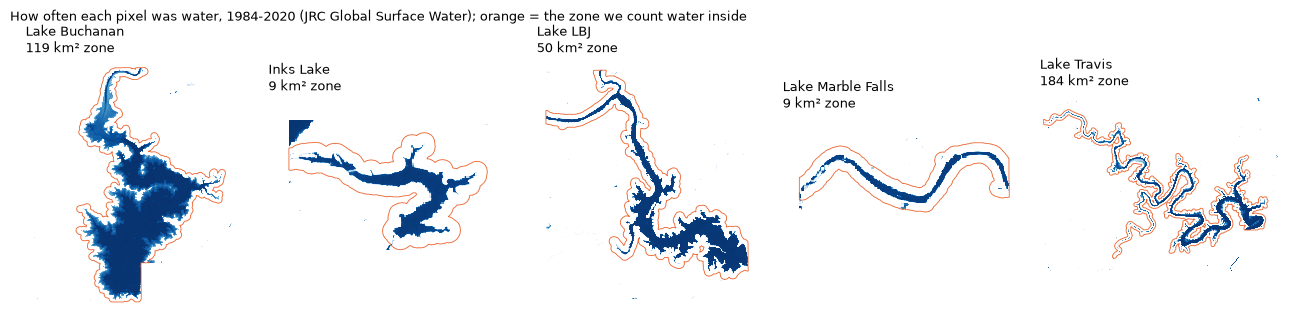

In [2]:
from hlw import aoi

fig, axes = plt.subplots(1, 5, figsize=(13, 3.2))
for ax, (k, lake) in zip(axes, LAKES.items()):
    zone, transform, crs = aoi.load_zone(k)
    occ = aoi.load_jrc(k).astype(float)
    occ[occ == 0] = np.nan
    ax.imshow(occ, cmap="Blues", vmin=0, vmax=100, interpolation="nearest")
    ax.contour(zone, [0.5], colors=ORANGE, linewidths=0.6)
    ax.set_title(f"{lake.name}\n{zone.sum() * 1e-4:.0f} km² zone", fontsize=9)
    ax.set_axis_off()
fig.suptitle("How often each pixel was water, 1984-2020 (JRC Global Surface Water); orange = the "
             "zone we count water inside", fontsize=9.5, x=0.01, ha="left")
plt.tight_layout()

The blue shading is the [JRC Global Surface Water](https://global-surface-water.appspot.com/)
*occurrence* layer: the share of 36 years of Landsat observations in which each pixel was
water. Dark blue is the permanent core; pale blue is the band of shore that is only sometimes
flooded. Almost all of the interesting change happens in that pale band.

The orange line is the **zone**: everywhere JRC has ever seen water, plus a 300 m buffer, cut
at the dams so lakes don't overlap. Counting water only inside a fixed zone does two jobs:
it stops a model getting credit (or blame) for stock tanks and rivers miles away, and it gives
every method exactly the same area to work in.

## The "official" area is a function of the water level

TWDB publishes a daily record for each reservoir: water level (ft above sea level), storage,
and **surface area** (acres). It is tempting to treat `surface_area` as the truth we are trying
to reproduce. Look at how it relates to the level:

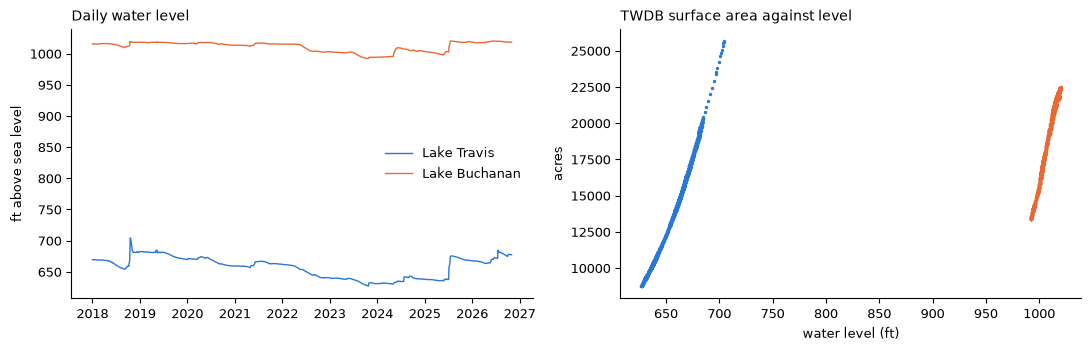

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for k, c in (("travis", BLUE), ("buchanan", ORANGE)):
    lv = levels.load(k)
    axes[0].plot(lv.index, lv.water_level, color=c, lw=1, label=LAKES[k].name)
    axes[1].scatter(lv.water_level, lv.surface_area, s=2, color=c, label=LAKES[k].name)
axes[0].set(title="Daily water level", ylabel="ft above sea level")
axes[1].set(title="TWDB surface area against level", xlabel="water level (ft)", ylabel="acres")
axes[0].legend(frameon=False)
plt.tight_layout()

The right panel is a perfectly thin curve, with no scatter at all. That's because TWDB doesn't
measure area. It **looks area up from the level** using an elevation-area table (a *rating
curve*) built from the last bathymetric survey of the lake bed.

This has consequences we will meet again:
* "Does mapped area track the official area?" is really "does it track the **water level**,
  pushed through a fixed curve?" A good map should correlate strongly with level, but it can
  legitimately differ from the curve's absolute numbers, because the survey and the satellite
  draw the shoreline differently (vegetation, mud, river arms).
* If the lake bed changes (sediment, a new survey), the curve changes and the "official" area
  can jump overnight with no change in water. We find exactly that on the small lakes in
  notebook 7.

So the honest framing is: TWDB level is excellent ground truth for **when** the lake grew or
shrank, and only approximate ground truth for **how many acres** it covers.

## How much drama is there to map?

In [4]:
rows = []
for k in LAKES:
    lv = levels.load(k)
    a, h = lv.surface_area, lv.water_level
    # 5th-95th percentiles describe the usual range; min/max also catch rare events
    rows.append({"lake": LAKES[k].name,
                 "usual level range, ft (5-95 %)": h.quantile(0.95) - h.quantile(0.05),
                 "usual area swing (5-95 %)": f"{(a.quantile(.95) - a.quantile(.05)) / a.quantile(.95):.0%}",
                 "min area (ac)": a.min(), "max area (ac)": a.max()})
pd.DataFrame(rows).round(1)

,lake,"usual level range, ft (5-95 %)",usual area swing (5-95 %),min area (ac),max area (ac)
0,Lake Buchanan,24.7,37%,13344.5,22458.9
1,Inks Lake,0.5,6%,525.3,1011.6
2,Lake LBJ,0.4,6%,5300.8,6422.2
3,Lake Marble Falls,5.1,28%,286.4,614.5
4,Lake Travis,49.8,52%,8746.6,25660.6


Lake Travis lost about **two thirds of its surface** between the October 2018 flood peak and
the October 2023 drought low, and refilled after the July 2025 floods. Buchanan swings by up
to 40 %.

The three pass-through lakes *usually* sit within a foot or so of their normal level, a few
percent in area. Their min/max columns look dramatic only because of rare events: the October
2018 flood and a handful of deliberate winter drawdowns lasting weeks. This is why the timeline
comparisons focus on Travis and Buchanan. On the other three, the everyday signal is smaller
than the mapping noise, and the rare events are seen on only a few clear dates (notebook 7).

## What the satellites give us

**Sentinel-2** (optical, 10 m) passes every 5 days. **Sentinel-1** (radar, 10 m) passes every
6-12 days and sees through cloud, because microwaves pass through water droplets. We
scanned every Sentinel-2 day from 2018 to 2026 and measured, from the Scene Classification
Layer (SCL) that comes with the imagery, what fraction of each lake's zone was free of cloud
and shadow.

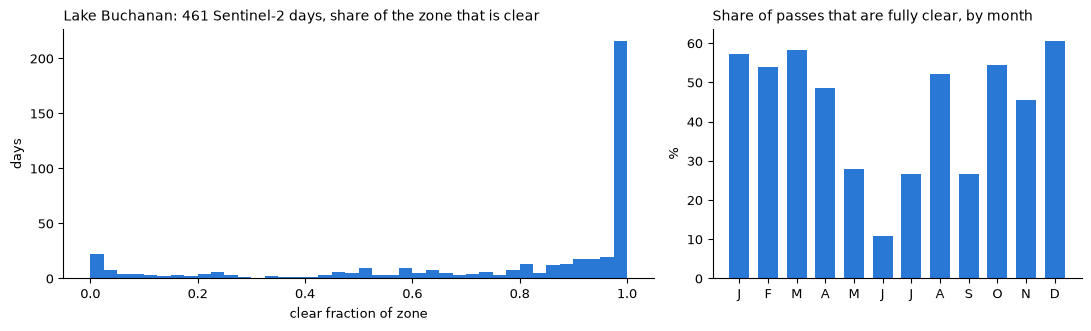

In [5]:
s2 = scenes.load("s2", "buchanan").dropna(subset=["clear_frac"])
s2["date"] = pd.to_datetime(s2.date)
s2["month"] = s2.date.dt.month
s2["clear"] = s2.clear_frac >= 0.99
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].hist(s2.clear_frac, bins=40, color=BLUE)
axes[0].set(title=f"Lake Buchanan: {len(s2)} Sentinel-2 days, share of the zone that is clear",
            xlabel="clear fraction of zone", ylabel="days")
m = s2.groupby("month").clear.mean()
axes[1].bar(m.index, 100 * m.values, color=BLUE, width=0.7)
axes[1].set(title="Share of passes that are fully clear, by month", xticks=range(1, 13),
            xticklabels=list("JFMAMJJASOND"), ylabel="%")
plt.tight_layout()

One detail of the inventory: the scan skipped passes whose whole Sentinel-2 tile was more than
80 % cloudy, so fully overcast days are mostly missing from this histogram. Among the passes
that remain, the commonest outcome by far is a **perfectly clear lake** (the spike at 1.0).
That is why we can afford a strict rule (use a date only if at least 99 % of the zone is
clear) and still keep hundreds of dates.

The monthly bars show the catch. Clear passes are rarest from **May to July and in
September**: late spring is Central Texas's wettest season, and summer brings haze and
afternoon cumulus. Those are also the months of the big floods (May-June and the
September-October tropical season). Optical-only monitoring goes blind just when the lake
can change fastest, and that's the case for radar.

In [6]:
rows = []
for k in LAKES:
    s2k = scenes.load("s2", k).dropna(subset=["clear_frac"])
    s1k = scenes.load("s1", k)
    months = pd.period_range(C.load_config()["study_start"], C.load_config()["study_end"], freq="M")
    clear_m = set(pd.to_datetime(s2k[s2k.clear_frac >= 0.99].date).dt.to_period("M"))
    s1_m = set(pd.to_datetime(s1k.date).dt.to_period("M"))
    rows.append({"lake": LAKES[k].name, "S2 days": len(s2k),
                 "S2 fully clear": int((s2k.clear_frac >= 0.99).sum()), "S1 days": len(s1k),
                 "months with a clear S2": f"{len(clear_m & set(months)) / len(months):.0%}",
                 "months with S2 or S1": f"{len((clear_m | s1_m) & set(months)) / len(months):.0%}"})
pd.DataFrame(rows)

,lake,S2 days,S2 fully clear,S1 days,months with a clear S2,months with S2 or S1
0,Lake Buchanan,461,193,253,84%,100%
1,Inks Lake,498,230,253,90%,100%
2,Lake LBJ,499,192,255,83%,100%
3,Lake Marble Falls,461,197,255,89%,100%
4,Lake Travis,956,146,255,70%,100%


About 40 % of Sentinel-2 days are fully clear at most lakes. Travis looks worse (15 %) for a
geometric reason, not a weather one. It sits where two orbit tracks overlap, so it gets a pass
every 2-3 days, but half of those passes only clip the edge of the lake, and a partial view
never counts as clear. That is also why Travis has twice as many "days".

The column that matters is the last but one. At Travis almost **one month in three** has no
fully clear optical view at all; at the others it is one in six to one in ten. Adding
Sentinel-1 fills every month.

(The radar record has a gap of its own: Sentinel-1B failed in December 2021, which halved the
revisit until Sentinel-1C arrived in 2025. Every month still has at least one pass.)

## Takeaways

* The reference is **level plus a rating curve**, not a measured area. Expect high correlations
  with level and some systematic offset in acres, and don't over-interpret the offset.
* The interesting pixels are the **shoreline band**. Open water and dry land are easy.
  Keep this in mind when we design the evaluation (notebook 3).
* Optical data is plentiful but **blind in exactly the wet months**. Radar's value is
  continuity, and we should measure it as such.

Next: [2 · pixels and water indices](02_pixels_and_indices.ipynb)